# Life Expectancy (WHO) — End-to-End OLS, Regularization & Ensemble Benchmark

In [1]:
# Core imports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 140)
sns.set_style('whitegrid')
plt.rcParams['figure.dpi'] = 100
np.random.seed(42)

## Step 1 — Load and Initial Data Hygiene

In [2]:
# 1.1 Load dataset
df = pd.read_csv("D:/Python programming/Projects/LIfe Expectancy Prediction Using Linear Regression/Life Expectancy Data (1).csv")

# 1.2 Strip whitespace from column names
df.columns = df.columns.str.strip()

# 1.3 Initial inspection
print(f"Shape: {df.shape}")
df.head()

Shape: (2938, 22)


,Country,Year,Status,Life expectancy,Adult Mortality,infant deaths,Alcohol,percentage expenditure,Hepatitis B,Measles,BMI,under-five deaths,Polio,Total expenditure,Diphtheria,HIV/AIDS,GDP,Population,thinness 1-19 years,thinness 5-9 years,Income composition of resources,Schooling
0,Afghanistan,2015,Developing,65.0,263.0,62,0.01,71.279624,65.0,1154,19.1,83,6.0,8.16,65.0,0.1,584.259210,33736494.0,17.2,17.3,0.479,10.1
1,Afghanistan,2014,Developing,59.9,271.0,64,0.01,73.523582,62.0,492,18.6,86,58.0,8.18,62.0,0.1,612.696514,327582.0,17.5,17.5,0.476,10.0
2,Afghanistan,2013,Developing,59.9,268.0,66,0.01,73.219243,64.0,430,18.1,89,62.0,8.13,64.0,0.1,631.744976,31731688.0,17.7,17.7,0.470,9.9
3,Afghanistan,2012,Developing,59.5,272.0,69,0.01,78.184215,67.0,2787,17.6,93,67.0,8.52,67.0,0.1,669.959000,3696958.0,17.9,18.0,0.463,9.8
4,Afghanistan,2011,Developing,59.2,275.0,71,0.01,7.097109,68.0,3013,17.2,97,68.0,7.87,68.0,0.1,63.537231,2978599.0,18.2,18.2,0.454,9.5


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2938 entries, 0 to 2937
Data columns (total 22 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   Country                          2938 non-null   str    
 1   Year                             2938 non-null   int64  
 2   Status                           2938 non-null   str    
 3   Life expectancy                  2928 non-null   float64
 4   Adult Mortality                  2928 non-null   float64
 5   infant deaths                    2938 non-null   int64  
 6   Alcohol                          2744 non-null   float64
 7   percentage expenditure           2938 non-null   float64
 8   Hepatitis B                      2385 non-null   float64
 9   Measles                          2938 non-null   int64  
 10  BMI                              2904 non-null   float64
 11  under-five deaths                2938 non-null   int64  
 12  Polio                          

In [4]:
print("Columns:")
print(df.columns.tolist())

Columns:
['Country', 'Year', 'Status', 'Life expectancy', 'Adult Mortality', 'infant deaths', 'Alcohol', 'percentage expenditure', 'Hepatitis B', 'Measles', 'BMI', 'under-five deaths', 'Polio', 'Total expenditure', 'Diphtheria', 'HIV/AIDS', 'GDP', 'Population', 'thinness  1-19 years', 'thinness 5-9 years', 'Income composition of resources', 'Schooling']


In [5]:
# 1.4 Identify variable roles
target = 'Life expectancy'
categorical_vars = ['Country', 'Status']
numerical_vars = [c for c in df.columns if c not in categorical_vars + [target]]

print(f"Target: {target}")
print(f"Categorical predictors: {categorical_vars}")
print(f"Numerical predictors ({len(numerical_vars)}): {numerical_vars}")

Target: Life expectancy
Categorical predictors: ['Country', 'Status']
Numerical predictors (19): ['Year', 'Adult Mortality', 'infant deaths', 'Alcohol', 'percentage expenditure', 'Hepatitis B', 'Measles', 'BMI', 'under-five deaths', 'Polio', 'Total expenditure', 'Diphtheria', 'HIV/AIDS', 'GDP', 'Population', 'thinness  1-19 years', 'thinness 5-9 years', 'Income composition of resources', 'Schooling']


In [6]:
# 1.5 Drop 'Country' - high-cardinality nominal (193 unique values) -> overfitting / dummy explosion risk
print(f"Unique countries: {df['Country'].nunique()}")
df = df.drop(columns=['Country'])
print(f"Shape after dropping Country: {df.shape}")

Unique countries: 193
Shape after dropping Country: (2938, 21)


In [7]:
# 1.6 Check and remove duplicate rows
n_dupes = df.duplicated().sum()
print(f"Duplicate rows found: {n_dupes}")
df = df.drop_duplicates().reset_index(drop=True)
print(f"Shape after de-duplication: {df.shape}")

Duplicate rows found: 0
Shape after de-duplication: (2938, 21)


In [8]:
# 1.7 Drop rows with missing target
n_missing_target = df['Life expectancy'].isnull().sum()
print(f"Rows with missing target: {n_missing_target}")
df = df.dropna(subset=['Life expectancy']).reset_index(drop=True)
print(f"Final shape after target-null drop: {df.shape}")

Rows with missing target: 10
Final shape after target-null drop: (2928, 21)


## Step 2 — Train-Test Split & Missing Values Imputation

In [9]:
from sklearn.model_selection import train_test_split

X = df.drop(columns=['Life expectancy'])
y = df['Life expectancy']

X = df.drop(columns=['Life expectancy'])
y = df['Life expectancy']

X_train = X[X['Year'] <= 2012]
X_test = X[X['Year'] > 2012]

y_train = y[X['Year'] <= 2012]
y_test = y[X['Year'] > 2012]

print(f"X_train: {X_train.shape}  X_test: {X_test.shape}")
print(f"y_train: {y_train.shape}  y_test: {y_test.shape}")

X_train: (2379, 20)  X_test: (549, 20)
y_train: (2379,)  y_test: (549,)


In [10]:
# 2.2 Check missing values before imputation (train set)
X_train.isnull().sum().sort_values(ascending=False)

Hepatitis B                        523
Population                         521
GDP                                358
Income composition of resources    130
Schooling                          130
Total expenditure                   41
BMI                                 26
thinness 5-9 years                  26
thinness  1-19 years                26
Polio                               19
Diphtheria                          19
Alcohol                             14
infant deaths                        0
Adult Mortality                      0
Status                               0
Year                                 0
under-five deaths                    0
Measles                              0
percentage expenditure               0
HIV/AIDS                             0
dtype: int64

In [11]:
# Column groups per domain-specific imputation strategy
median_impute_cols = ['Polio', 'Diphtheria', 'BMI','thinness  1-19 years', 'thinness 5-9 years','Hepatitis B', 'GDP', 'Population', 'Alcohol']
mean_impute_cols = ['Total expenditure','Income composition of resources', 'Schooling']

# Function to calculate group-wise mean or median
def fit_group_stats(train_df, cols, method='median'):
    if method == 'median':
        return train_df.groupby('Status')[cols].median()
    else:
        return train_df.groupby('Status')[cols].mean()

# Function to fill missing values
def apply_group_impute(target_df, cols, stats):
    out = target_df.copy()
    for col in cols:
        out[col] = out[col].fillna(out['Status'].map(stats[col]))
    return out

# Calculate statistics using training data only
median_stats = fit_group_stats(X_train, median_impute_cols, 'median')
mean_stats = fit_group_stats(X_train, mean_impute_cols, 'mean')

# Apply imputation on training data
X_train = apply_group_impute(X_train, median_impute_cols, median_stats)
X_train = apply_group_impute(X_train, mean_impute_cols, mean_stats)


# Apply imputation on testing data
X_test = apply_group_impute(X_test, median_impute_cols, median_stats)
X_test = apply_group_impute(X_test, mean_impute_cols, mean_stats)

## Step 3 — Detailed Exploratory Data Analysis (EDA)

In [12]:
# Combine train predictors + target for EDA only (never used for fitting)
eda_df = X_train.copy()
eda_df['Life expectancy'] = y_train.values
print(eda_df.shape)

(2379, 21)


### 3.1 Target Variable — Life Expectancy

In [13]:
# Summary statistics
target_stats = eda_df['Life expectancy'].describe()
iqr = target_stats['75%'] - target_stats['25%']
print(target_stats)
print(f"IQR: {iqr:.2f}")

count    2379.000000
mean       68.708407
std         9.702414
min        36.300000
25%        62.500000
50%        71.900000
75%        75.300000
max        89.000000
Name: Life expectancy, dtype: float64
IQR: 12.80


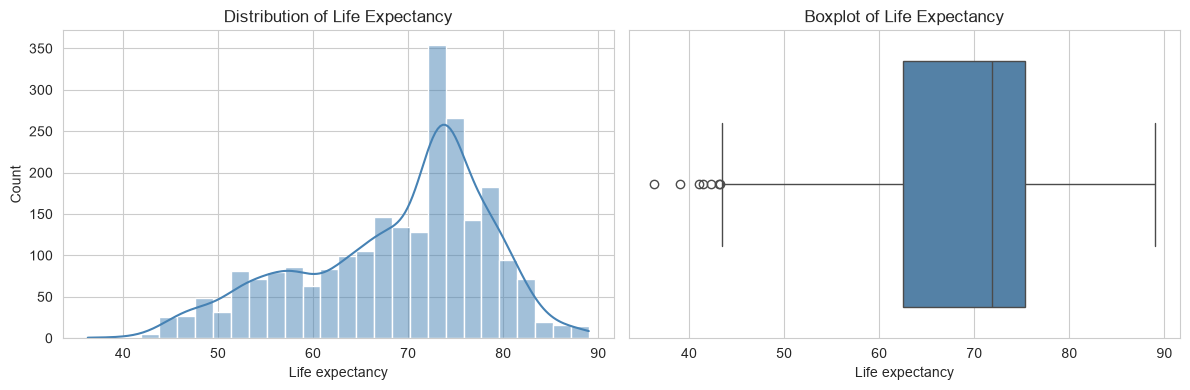

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(eda_df['Life expectancy'], kde=True, ax=axes[0], color='steelblue')
axes[0].set_title('Distribution of Life Expectancy')
sns.boxplot(x=eda_df['Life expectancy'], ax=axes[1], color='steelblue')
axes[1].set_title('Boxplot of Life Expectancy')
plt.tight_layout()
plt.show()

### 3.2 Categorical Feature — Status

Status
Developing    1963
Developed      416
Name: count, dtype: int64


C:\Users\kushw\AppData\Local\Temp\ipykernel_12700\3902801960.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='Status', data=eda_df, palette='Set2')


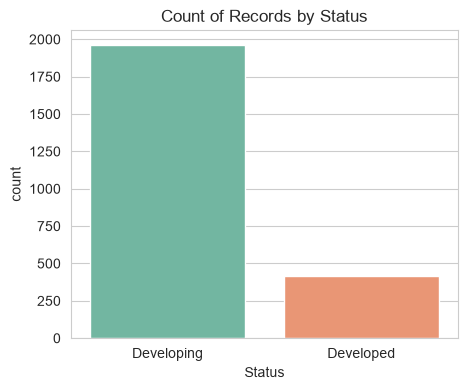

In [15]:
print(eda_df['Status'].value_counts())
plt.figure(figsize=(5,4))
sns.countplot(x='Status', data=eda_df, palette='Set2')
plt.title('Count of Records by Status')
plt.show()

C:\Users\kushw\AppData\Local\Temp\ipykernel_12700\3161679052.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Status', y='Life expectancy', data=eda_df, palette='Set2')


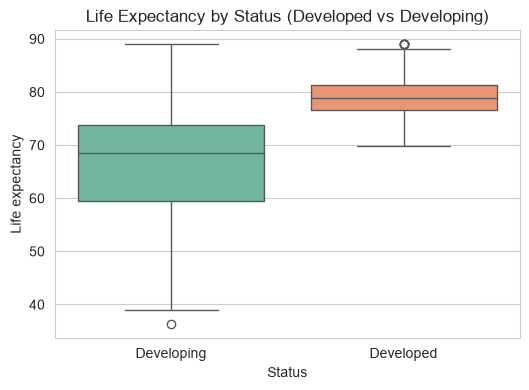

In [16]:
plt.figure(figsize=(6,4))
sns.boxplot(x='Status', y='Life expectancy', data=eda_df, palette='Set2')
plt.title('Life Expectancy by Status (Developed vs Developing)')
plt.show()

### 3.3 Numerical Predictors

In [17]:
num_predictors = [c for c in eda_df.columns if c not in ['Status', 'Life expectancy']]
eda_df[num_predictors].describe().T

,count,mean,std,min,25%,50%,75%,max
Year,2379.0,2.006000e+03,3.742444e+00,2000.00000,2003.000000,2.006000e+03,2.009000e+03,2.012000e+03
Adult Mortality,2379.0,1.681866e+02,1.284255e+02,1.00000,75.000000,1.450000e+02,2.320000e+02,7.230000e+02
infant deaths,2379.0,3.175998e+01,1.241902e+02,0.00000,0.000000,3.000000e+00,2.300000e+01,1.800000e+03
Alcohol,2379.0,4.746679e+00,4.003071e+00,0.01000,1.200000,3.880000e+00,7.805000e+00,1.787000e+01
percentage expenditure,2379.0,7.665942e+02,1.967791e+03,0.00000,10.424665,7.631868e+01,4.680644e+02,1.896135e+04
Hepatitis B,2379.0,8.296679e+01,2.299172e+01,1.00000,83.000000,9.100000e+01,9.500000e+01,9.900000e+01
Measles,2379.0,2.613609e+03,1.211315e+04,0.00000,0.000000,1.800000e+01,4.225000e+02,2.121830e+05
BMI,2379.0,3.743165e+01,1.958576e+01,1.00000,18.800000,4.220000e+01,5.530000e+01,7.620000e+01
under-five deaths,2379.0,4.432114e+01,1.695659e+02,0.00000,0.000000,4.000000e+00,3.000000e+01,2.500000e+03
Polio,2379.0,8.221396e+01,2.347015e+01,3.00000,77.000000,9.300000e+01,9.700000e+01,9.900000e+01


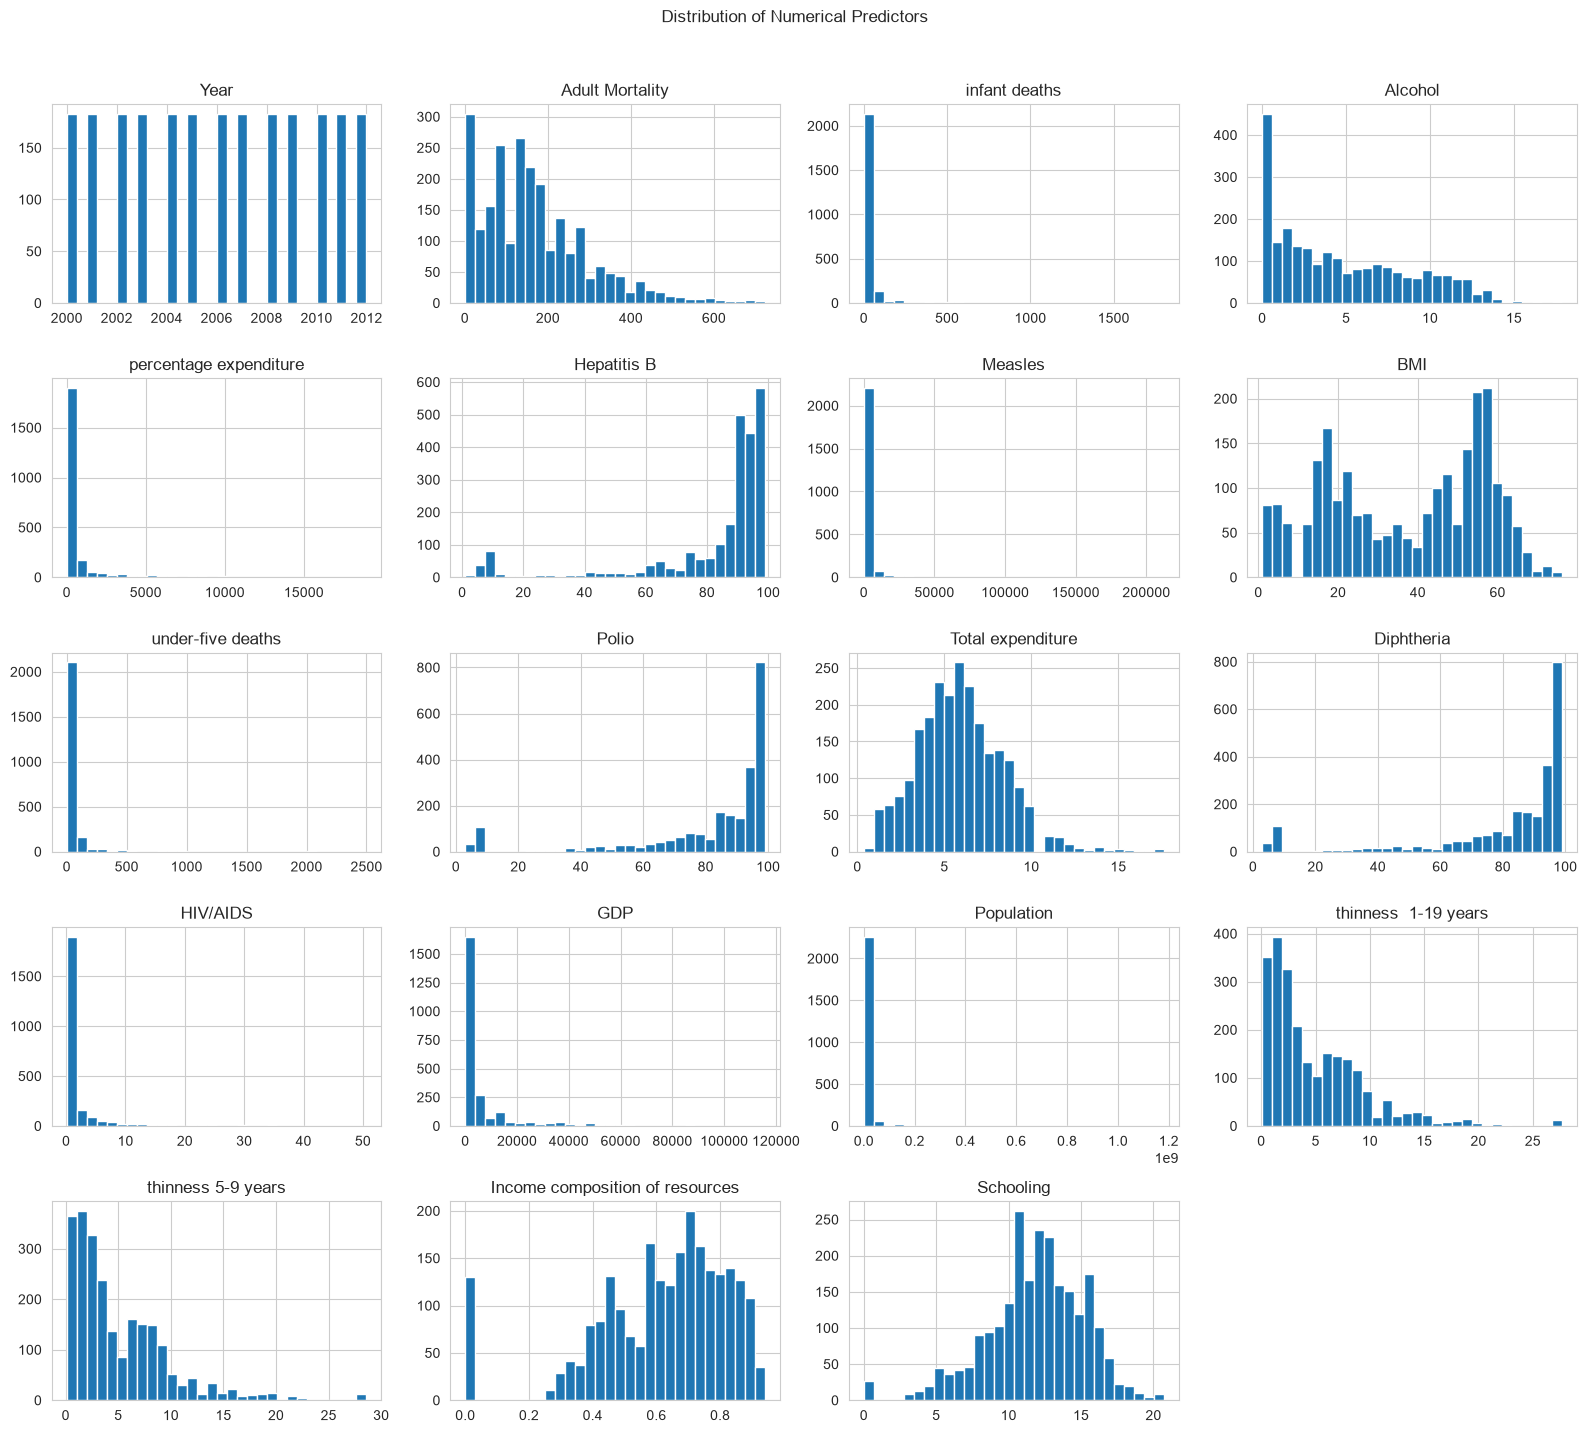

In [18]:
eda_df[num_predictors].hist(figsize=(16, 14), bins=30, layout=(5,4))
plt.suptitle('Distribution of Numerical Predictors', y=1.02)
plt.tight_layout()
plt.show()

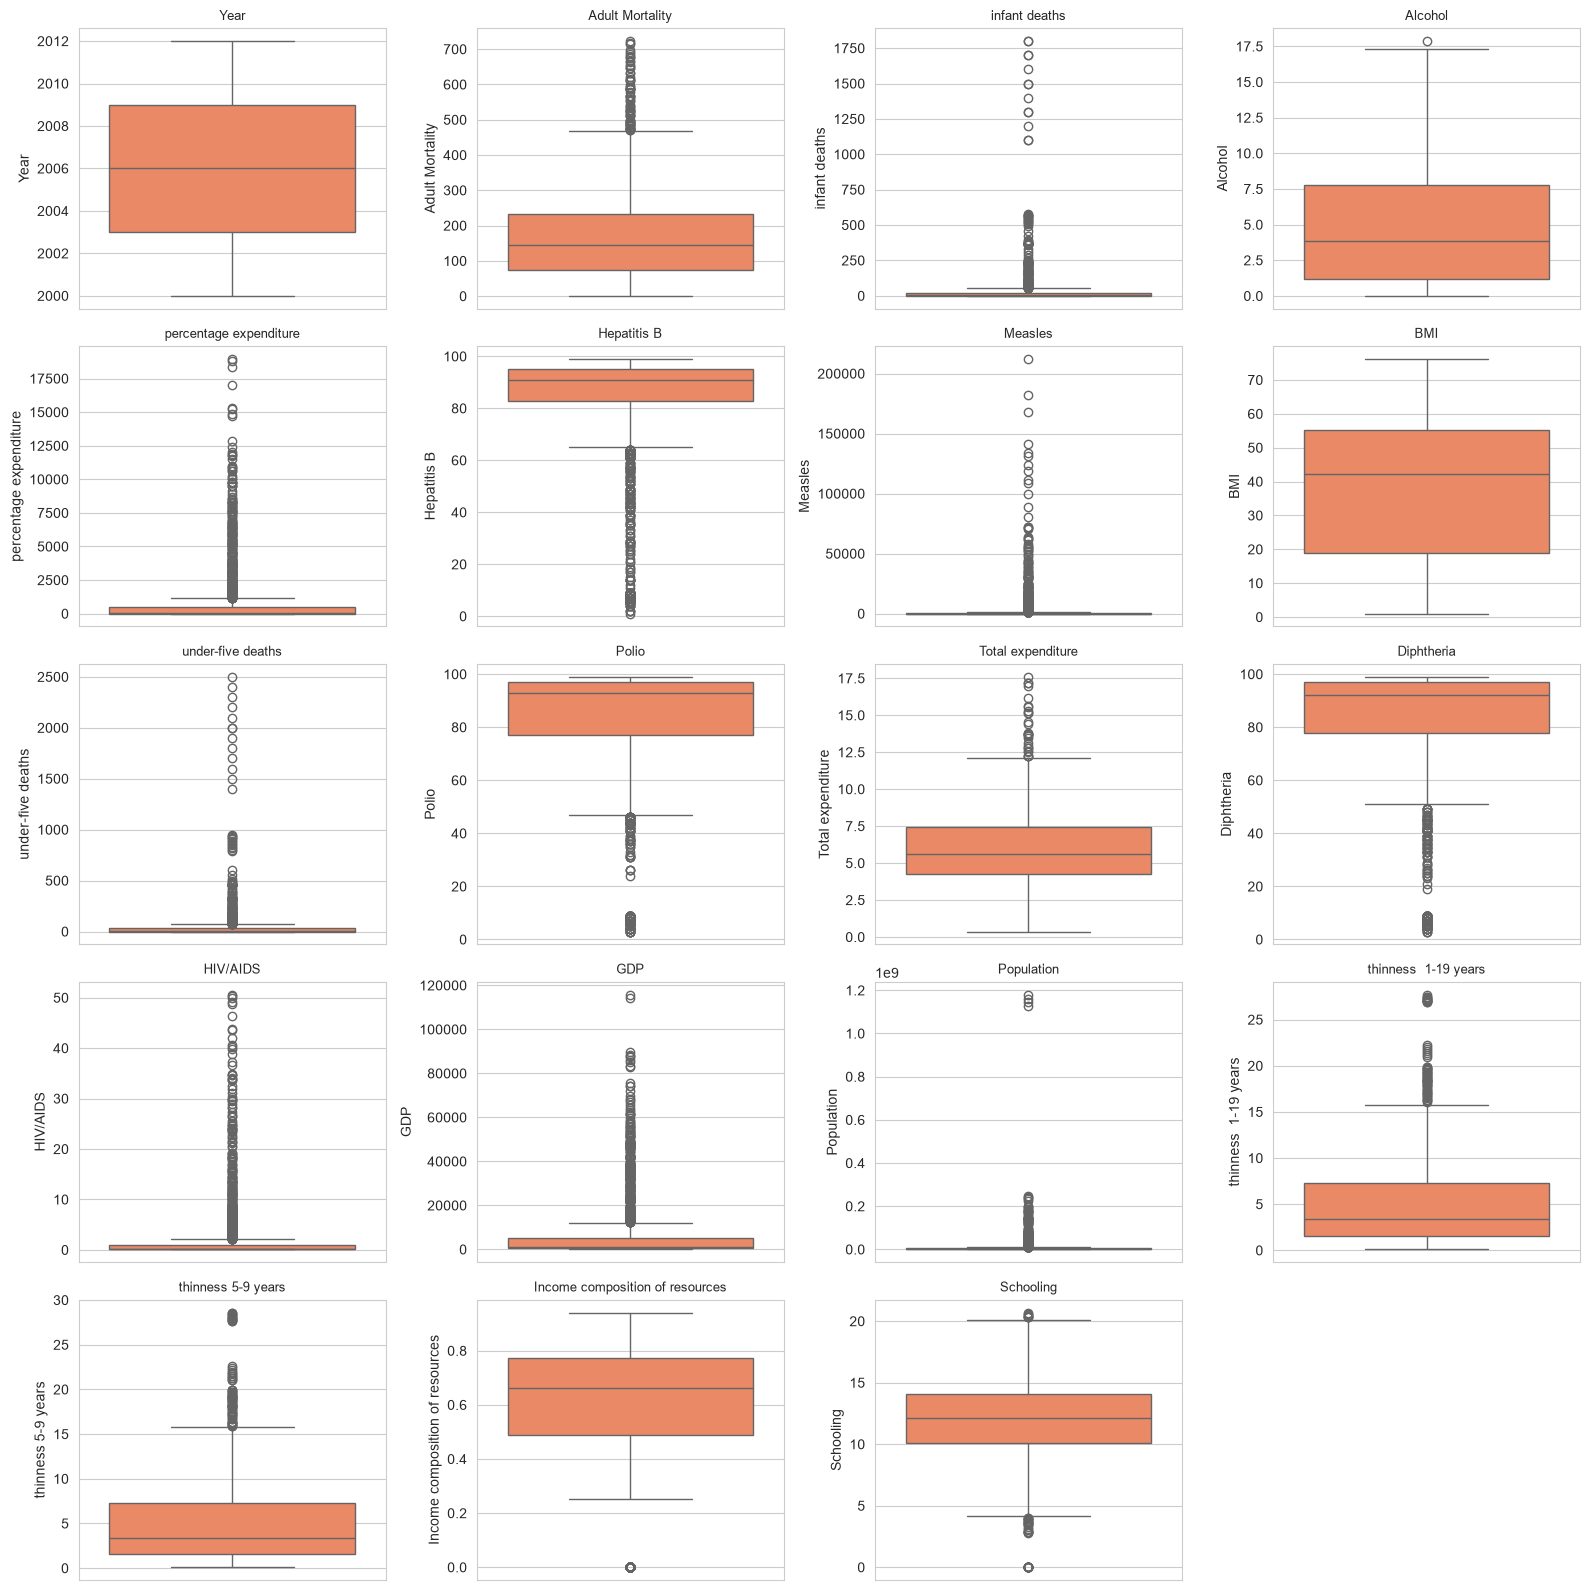

In [19]:
fig, axes = plt.subplots(5, 4, figsize=(16, 16))
axes = axes.flatten()
for i, col in enumerate(num_predictors):
    sns.boxplot(y=eda_df[col], ax=axes[i], color='coral')
    axes[i].set_title(col, fontsize=9)
for j in range(len(num_predictors), len(axes)):
    axes[j].axis('off')
plt.tight_layout()
plt.show()

### 3.4 Bivariate Analysis — Key Predictors vs Life Expectancy

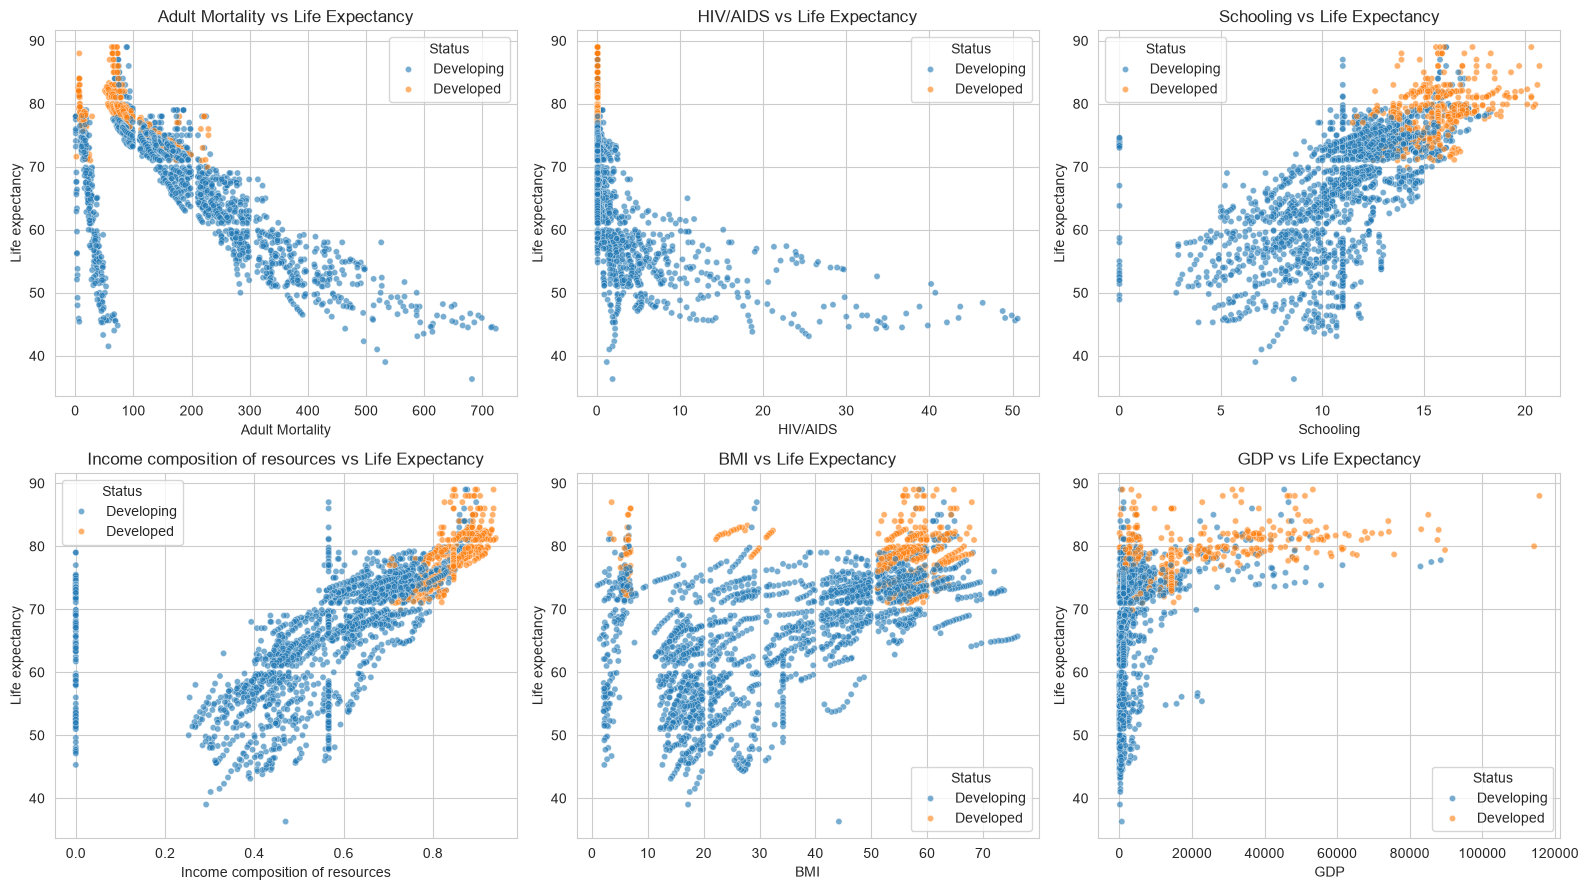

In [20]:
key_predictors = ['Adult Mortality', 'HIV/AIDS', 'Schooling',
                   'Income composition of resources', 'BMI', 'GDP']

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()
for i, col in enumerate(key_predictors):
    sns.scatterplot(x=eda_df[col], y=eda_df['Life expectancy'], hue=eda_df['Status'], ax=axes[i], alpha=0.6, s=20)
    axes[i].set_title(f'{col} vs Life Expectancy')
plt.tight_layout()
plt.show()

### 3.5 Multivariate Analysis — Correlation Heatmap

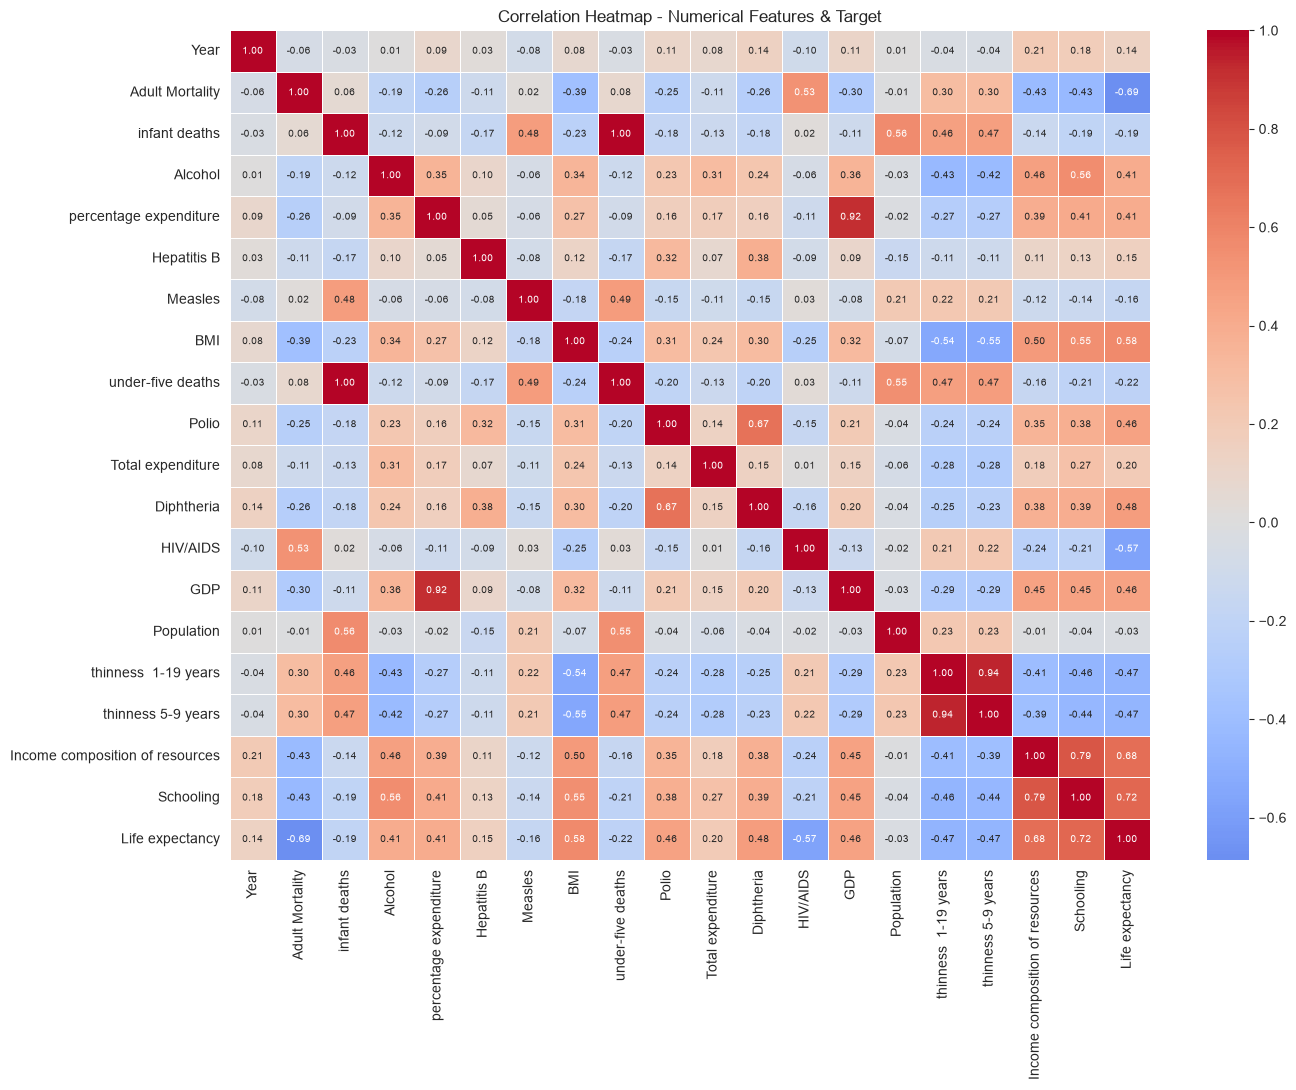

In [21]:
corr_matrix = eda_df[num_predictors + ['Life expectancy']].corr()

plt.figure(figsize=(14, 11))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', center=0, linewidths=0.4, annot_kws={'size':7})
plt.title('Correlation Heatmap - Numerical Features & Target')
plt.tight_layout()
plt.show()

In [22]:
target_corr = corr_matrix['Life expectancy'].drop('Life expectancy').sort_values(ascending=False)
print("Top 5 POSITIVE correlations with Life Expectancy:")
print(target_corr.head(5))
print("\nTop 5 NEGATIVE correlations with Life Expectancy:")
print(target_corr.tail(5))

Top 5 POSITIVE correlations with Life Expectancy:
Schooling                          0.723228
Income composition of resources    0.684238
BMI                                0.576602
Diphtheria                         0.476179
Polio                              0.459506
Name: Life expectancy, dtype: float64

Top 5 NEGATIVE correlations with Life Expectancy:
under-five deaths      -0.216143
thinness 5-9 years     -0.465205
thinness  1-19 years   -0.473020
HIV/AIDS               -0.569920
Adult Mortality        -0.686753
Name: Life expectancy, dtype: float64


## Step 4 — Feature Engineering & Multicollinearity (VIF)

In [23]:
# 4.1 Drop redundant collinear pairs (keep the more granular / commonly-used member of each pair)
print("Corr(under-five deaths, infant deaths):", eda_df['under-five deaths'].corr(eda_df['infant deaths']))
print("Corr(thinness 5-9 years, thinness 1-19 years):", eda_df['thinness 5-9 years'].corr(eda_df['thinness  1-19 years']))

X_train = X_train.drop(columns=['under-five deaths', 'thinness 5-9 years', "infant deaths", "Adult Mortality", "Income composition of resources"])
X_test = X_test.drop(columns=['under-five deaths', 'thinness 5-9 years', "infant deaths", "Adult Mortality", "Income composition of resources"])
print(f"Shape after dropping redundant features: {X_train.shape}")

Corr(under-five deaths, infant deaths): 0.9968383628569407
Corr(thinness 5-9 years, thinness 1-19 years): 0.93701817807418
Shape after dropping redundant features: (2379, 15)


In [24]:
# 4.2 Log-transform heavily right-skewed economic predictors: log(1+x)
skewed_cols = ['GDP', 'percentage expenditure', 'Population']
for col in skewed_cols:
    X_train[f'log_{col}'] = np.log1p(X_train[col])
    X_test[f'log_{col}'] = np.log1p(X_test[col])

X_train = X_train.drop(columns=skewed_cols)
X_test = X_test.drop(columns=skewed_cols)
print(f"Shape after log-transform: {X_train.shape}")

Shape after log-transform: (2379, 15)


I applied log transformation to these three predictors because it significantly reduced the number of outliers in their boxplots. For the other skewed predictors, transformations were not as effective in handling outliers.
Also, linear regression does not require predictors to be normally distributed. So, I avoided unnecessary transformations and retained the remaining predictors in their original form.

In [25]:
# 4.3 Encode Status: Developing=0 (reference), Developed=1
status_map = {'Developing': 0, 'Developed': 1}
X_train['Status'] = X_train['Status'].map(status_map)
X_test['Status'] = X_test['Status'].map(status_map)
X_train['Status'].value_counts()

Status
0    1963
1     416
Name: count, dtype: int64

In [26]:
# 4.4 Multicollinearity diagnostic - Variance Inflation Factor (VIF)
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor

def compute_vif(X_df):
    X_const = sm.add_constant(X_df)
    vif_data = pd.DataFrame()
    vif_data['Feature'] = X_const.columns
    vif_data['VIF'] = [variance_inflation_factor(X_const.values, i) for i in range(X_const.shape[1])]
    return vif_data[vif_data['Feature'] != 'const'].sort_values('VIF', ascending=False).reset_index(drop=True)

vif_table = compute_vif(X_train)
vif_table

,Feature,VIF
0,log_GDP,2.476530
1,Schooling,2.412211
2,Diphtheria,2.039337
3,Alcohol,1.974782
4,Polio,1.917124
5,Status,1.884730
6,log_percentage expenditure,1.840241
7,BMI,1.778316
8,thinness 1-19 years,1.671121
9,Hepatitis B,1.199001


In [27]:
# Iteratively drop any feature with VIF > 5 (highest first), re-checking after each drop
vif_current = vif_table.copy()
dropped_for_vif = []

while vif_current['VIF'].max() > 5:
    worst_feature = vif_current.sort_values('VIF', ascending=False).iloc[0]['Feature']
    dropped_for_vif.append(worst_feature)
    X_train = X_train.drop(columns=[worst_feature])
    X_test = X_test.drop(columns=[worst_feature])
    vif_current = compute_vif(X_train)

print(f"Features dropped for VIF > 5: {dropped_for_vif if dropped_for_vif else 'None (all VIF < 5 already)'}")

Features dropped for VIF > 5: None (all VIF < 5 already)


In [28]:
# Final VIF table - all features should have VIF < 5
final_vif_table = compute_vif(X_train)
final_vif_table

,Feature,VIF
0,log_GDP,2.476530
1,Schooling,2.412211
2,Diphtheria,2.039337
3,Alcohol,1.974782
4,Polio,1.917124
5,Status,1.884730
6,log_percentage expenditure,1.840241
7,BMI,1.778316
8,thinness 1-19 years,1.671121
9,Hepatitis B,1.199001


In [29]:
# 4.5 Feature scaling - fit StandardScaler on X_train ONLY, transform both splits
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = pd.DataFrame(
    scaler.fit_transform(X_train), columns=X_train.columns, index=X_train.index
)
X_test_scaled = pd.DataFrame(
    scaler.transform(X_test), columns=X_test.columns, index=X_test.index
)

print(f"X_train_scaled: {X_train_scaled.shape}")
print(f"X_test_scaled : {X_test_scaled.shape}")
X_train_scaled.describe().T[['mean', 'std']]

X_train_scaled: (2379, 15)
X_test_scaled : (549, 15)


,mean,std
Year,-2.240046e-18,1.00021
Status,3.584074e-17,1.00021
Alcohol,8.362840e-17,1.00021
Hepatitis B,-2.344582e-16,1.00021
Measles,-1.194691e-17,1.00021
BMI,1.836838e-16,1.00021
Polio,-2.747790e-16,1.00021
Total expenditure,1.792037e-17,1.00021
Diphtheria,5.077439e-17,1.00021
HIV/AIDS,4.778766e-17,1.00021


### Continues in Part 2 — 02_Model_Training_Evaluation.ipynb

In [ ]:
# Persist state for Part 2 (Model Training & Evaluation) — exact objects, no recomputation
import pickle

state = {
    'X_train': X_train,
    'X_test': X_test,
    'X_train_scaled': X_train_scaled,
    'X_test_scaled': X_test_scaled,
    'y_train': y_train,
    'y_test': y_test,
}

with open('life_expectancy_split_state.pkl', 'wb') as f:
    pickle.dump(state, f)

print('Saved state for Part 2:', list(state.keys()))

Saved state for Part 2: ['X_train', 'X_test', 'X_train_scaled', 'X_test_scaled', 'y_train', 'y_test']
